# Module 3 · Environmental Responses and Dynamic Light
**30 minutes: principles 6 · examples 8 · exercises 12 · discussion 4**

[Course introduction](00_Introduction.ipynb)

**Learning objectives:** define a time-dependent light input, handle its discontinuities,
compare environmental response curves and calculate cumulative net CO₂ uptake.

[Reference answers with runnable code](#reference-answer) are included at the end of this notebook.


**Extension practice:** 3D light × CO₂ (7 min), 3E temperature × CO₂ (7 min),
and 3F sunfleck pattern × CO₂ × temperature (10 min). These 24 minutes are
optional follow-up work; the core 90-minute course timetable is unchanged.
Each includes a guided workflow, runnable simulations and worked answers.


In [ ]:
# Locate c3_model for both local Jupyter and Kaggle sessions.
import sys
from pathlib import Path

_model_root = None
for _candidate in (Path.cwd(), *Path.cwd().parents):
    if (_candidate / "c3_model" / "__init__.py").is_file():
        _model_root = _candidate
        break

if _model_root is None:
    _matches = sorted(Path("/kaggle/input").glob("**/c3_model/__init__.py"))
    if _matches:
        _model_root = _matches[0].parent.parent

if _model_root is None:
    raise FileNotFoundError(
        "Cannot find c3_model/__init__.py. On Kaggle, add the dataset containing "
        "the complete c3_model folder via Add Input. Locally, start Jupyter "
        "from the project folder or its Course subfolder."
    )

if str(_model_root) not in sys.path:
    sys.path.insert(0, str(_model_root))
print("c3_model directory:", _model_root / "c3_model")


## 1. Principles · 6 min
The source model converts incident PAR into potential electron transport using a
nonrectangular hyperbola:
$$I_2=\frac{PAR}{30}\frac{\alpha(1-f_c)}{2},$$
$$J=\frac{I_2+J_{\max}-\sqrt{(I_2+J_{\max})^2-4\theta I_2J_{\max}}}{2\theta}.$$
The driver also divides the area-based Jmax25 by 30, retaining the source volume convention.
ATP production is bounded by 0.75 J and the ATP-synthase kinetic rate. The revised model
additionally accounts for ATP needed to reassimilate ammonia released by photorespiration.
Reductant demand is checked against the incident-light budget after settling.

Electron supply can respond algebraically to a change in light, whereas metabolite and ATP
pools evolve through differential equations. These pool dynamics produce the transients
examined here. NADPH remains buffered: this is not a model of measured NADPH induction,
NPQ relaxation or dynamic Rubisco activation.

To compare treatments, distinguish instantaneous assimilation from cumulative uptake:
$$C_{600}=\int_0^{600}A(t)\,dt.$$
Integrating A in µmol CO₂ m⁻² s⁻¹ over seconds gives µmol CO₂ m⁻². Divide by 1000 to
report mmol CO₂ m⁻². A high peak need not imply the greatest cumulative uptake.

## 2. Worked examples · 8 min
### Example A: a sunfleck
Start both treatments from a common low-light preconditioned state. Split the integration
exactly at the light transitions; the code links `breakpoints` to the sunfleck boundaries.

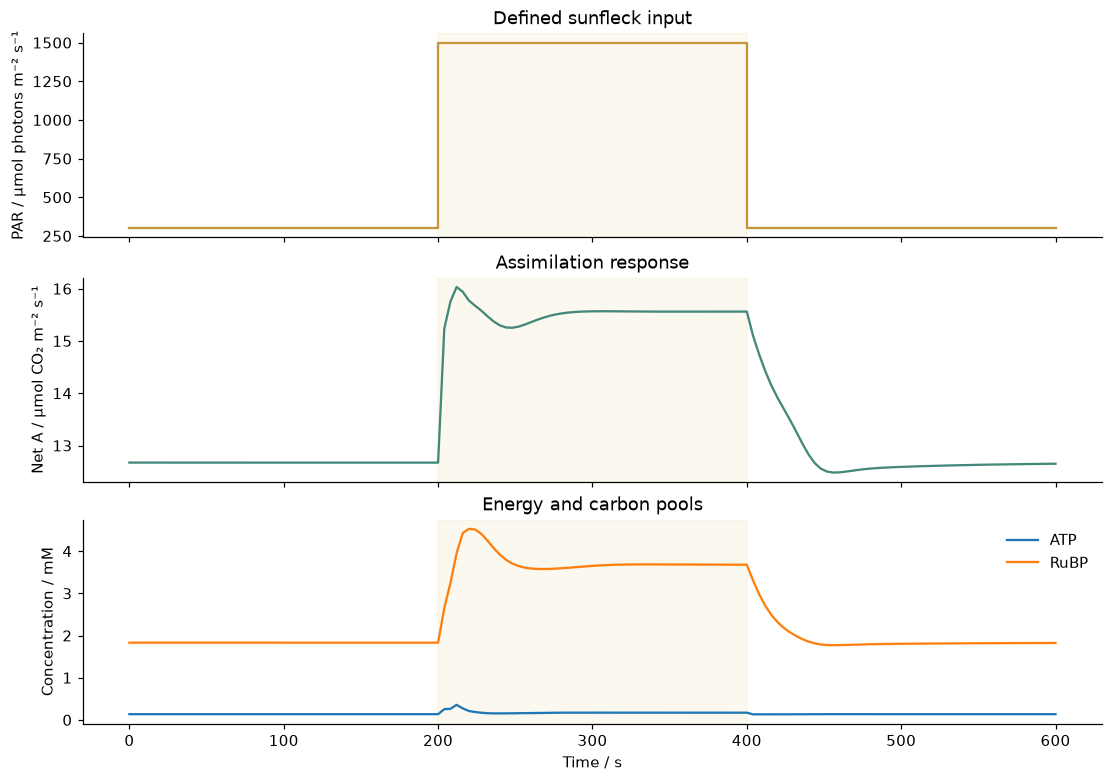

In [ ]:
from c3_model import C3Model, simulate
from c3_model.plots import style
import matplotlib.pyplot as plt
style()

low_light, high_light = 300, 1500  # EDIT: background and sunfleck PAR
start, end, duration = 200, 400, 600  # EDIT: onset, offset and total duration, s
assert 0 < start < end < duration
def sunfleck(t):
    return high_light if start <= t < end else low_light

warm = simulate(C3Model(light=low_light), 3000).states[-1]
run = simulate(C3Model(light=low_light), duration, initial=warm,
               light_program=sunfleck, breakpoints=[start, end])
fig, axes = plt.subplots(3, 1, figsize=(10, 7), sharex=True, constrained_layout=True)
axes[0].step(run.time, run.light, where='post', color='#c49539')
axes[0].set(ylabel='PAR / µmol photons m⁻² s⁻¹', title='Defined sunfleck input')
axes[1].plot(run.time, run.assimilation, color='#438879')
axes[1].set(ylabel='Net A / µmol CO₂ m⁻² s⁻¹', title='Assimilation response')
for name in ['ATP', 'RuBP']:
    axes[2].plot(run.time, run.concentration(name), label=name)
axes[2].set(xlabel='Time / s', ylabel='Concentration / mM', title='Energy and carbon pools')
axes[2].legend(frameon=False)
for ax in axes:
    ax.axvspan(start, end, color='#e6c981', alpha=.12)
plt.show()

### Example B: light, CO₂ and temperature responses
This code cell is also independent. Each environment is simulated for 3000 s from its
supplied initial state. The figure reports a final-time value; it does not automatically
establish that every metabolite has reached steady state. Changing Ci is not a simulation
of stomatal dynamics. The chosen temperature response is not universal across C3 species.

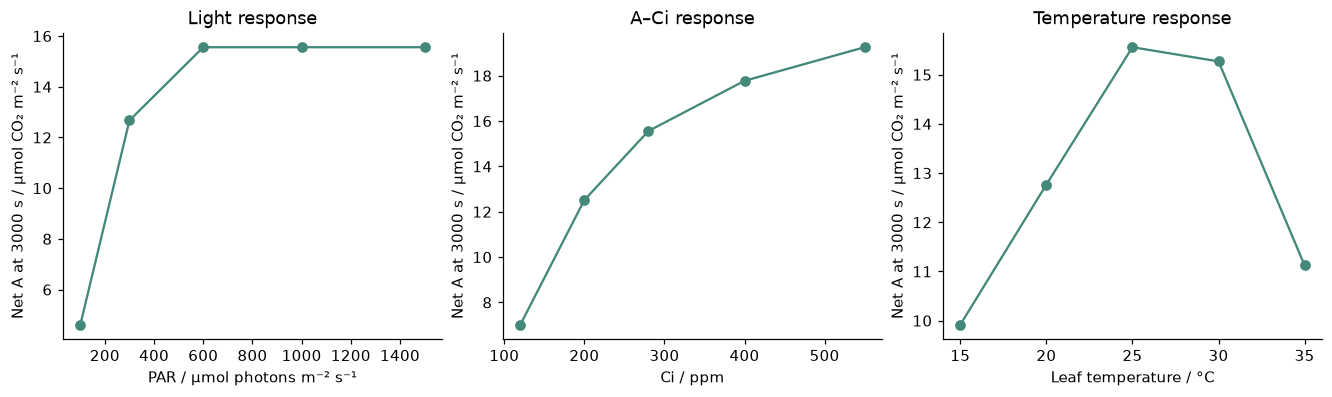

In [ ]:
from c3_model import C3Model, simulate
from c3_model.plots import style
import matplotlib.pyplot as plt
style()

lights = [100, 300, 600, 1000, 1500]  # EDIT: PAR
cis = [120, 200, 280, 400, 550]       # EDIT: intercellular CO₂, ppm
temperatures = [15, 20, 25, 30, 35]  # EDIT: leaf temperature, °C
def final_a(**environment):
    return simulate(C3Model(**environment), 3000).assimilation[-1]

light_a = [final_a(light=x) for x in lights]
ci_a = [final_a(ci=x) for x in cis]
temp_a = [final_a(temperature=x) for x in temperatures]
fig, axes = plt.subplots(1, 3, figsize=(12, 3.5), constrained_layout=True)
for ax, x, y, label, title in zip(axes, [lights, cis, temperatures],
        [light_a, ci_a, temp_a], ['PAR / µmol photons m⁻² s⁻¹', 'Ci / ppm', 'Leaf temperature / °C'],
        ['Light response', 'A–Ci response', 'Temperature response']):
    ax.plot(x, y, 'o-', color='#438879')
    ax.set(xlabel=label, ylabel='Net A at 3000 s / µmol CO₂ m⁻² s⁻¹', title=title)
plt.show()

## Before the exercises: an experiment checklist

**Start here.** Run the model-location cell near the top of this notebook. Then run
an exercise cell with Shift+Enter. Each new exercise imports its own dependencies.
Change the parameter values at the top of that cell and rerun the **whole cell**.
Tables and figures are generated even while the analysis TODOs are unfinished.

| Input | Python name | Meaning and unit | Suggested teaching values |
|---|---|---|---|
| Light | `light` | PAR, µmol photons m⁻² s⁻¹ | 300, 1000, 1200, 1500 |
| CO₂ | `ci` | Intercellular CO₂, ppm | 280, 550 |
| Leaf temperature | `temperature` | °C | 25, 35 |

`ci` is intercellular CO₂, not ambient CO₂. These experiments do not predict how
stomata translate ambient CO₂ into Ci. Ci and temperature are **constant within
each run**; the sunfleck experiments change light through time.

**Choose the output before making the comparison.**

| Question | Output | How to obtain it |
|---|---|---|
| What is net photosynthesis at the end? | Net A, µmol CO₂ m⁻² s⁻¹ | `run.assimilation[-1]` |
| What is the largest rate? | Peak A, same unit | `np.max(run.assimilation)` |
| How much CO₂ is taken up over the experiment? | C, mmol CO₂ m⁻² | `np.trapezoid(run.assimilation, run.time) / 1000` |

In Python, `[-1]` means the last value. The integral uses **all** time points;
neither the final rate nor the peak rate is cumulative carbon uptake.

**A two-factor question needs four treatments.** For light × CO₂, keep temperature,
enzyme amounts and duration fixed, and combine each light level with each Ci level.
First compare CO₂ treatments at the *same* light; then compare those two differences:

```text
CO2 effect at low light  = A(low light, high Ci) - A(low light, low Ci)
CO2 effect at high light = A(high light, high Ci) - A(high light, low Ci)
interaction             = effect at high light - effect at low light
```

A positive interaction means that the increase in Ci has a larger effect at the
higher light level **in this comparison**. Near zero means approximately additive
effects on this output scale. It is not a statistical significance test or a claim
about all light/CO₂ combinations. Avoid adding percentage changes together.

**Keep comparisons fair.** Static cases use each environment's supplied initialization
and the same 3000 s protocol; a final-time value is not proof that every pool has
reached steady state. For dynamic pairs, precondition at the background light
separately for each Ci/temperature combination and share that state between the
two light patterns. The helper does this for you.

The new exercises use the readable source `c3_model/environment_practical.py`.
It calls the same model, collects outputs and reuses identical calculations **in
memory**. Changing an environment or timing input gives a new calculation. After
editing Python source, restart the kernel and rerun the setup cell. No model
equations, species calibration, NPQ, stomatal dynamics or heat-damage process
have been added.


## 3. Core exercises · 12 min

**3A · Define the light input (4 min).** Return PAR = 1500 for
`200 <= t < 400` s and PAR = 300 otherwise. Supply both integration breakpoints.

Hints before you code:

1. Use `high_value if condition else background_value` inside the function.
2. The onset is included; the end is excluded. Test **both** boundaries.
3. Replace `breakpoints = None` with a list containing the two transition times.
4. The six test inputs below should return `[300, 300, 1500, 1500, 300, 300]`.

**3B · Compare equal-photon treatments (5 min).** Use background PAR = 300,
duration = 600 s and one shared low-light-preconditioned state:

| Treatment | High PAR | High-light interval / s | High-light duration / s |
|---|---:|---|---:|
| A | 1500 | 200 ≤ t < 400 | 200 |
| B | 1100 | 150 ≤ t < 450 | 300 |

Follow Example A, then use these steps:

1. Obtain the warm state **once** using `simulate(C3Model(light=300), 3000).states[-1]`.
2. Define each light function and pass its transition times as `breakpoints`.
3. Pass the same warm state as `initial=warm` for both simulations. Use a one-second
   output grid and include the switching times, as in the reference answer.
4. Calculate the photon dose and cumulative uptake using the two recipes below.
5. Record both treatments; do not infer cumulative uptake from the peak alone.

```text
photon dose = background PAR * total time
              + (high PAR - background PAR) * high-light duration
cumulative C = np.trapezoid(run.assimilation, run.time) / 1000
```

**Self-check:** both photon doses should be 420000 µmol photons m⁻². C is in
mmol CO₂ m⁻². Keep the photon dose in its own column; it is not a CO₂ flux.

| Treatment | Photon dose / µmol m⁻² | Peak A / µmol CO₂ m⁻² s⁻¹ | C / mmol CO₂ m⁻² |
|---|---:|---:|---:|
| A | 420000 | fill in | fill in |
| B | 420000 | fill in | fill in |

**3C · Explain the comparison (3 min).** Which pattern has the larger peak?
Which fixes more carbon over 600 s? Refer to your numbers and the time-course plot.
Light-response nonlinearity and metabolite-pool dynamics are available explanations
in this model. Do not attribute a difference to NPQ, stomatal movement or leaf
heating: those processes are not simulated here.

The optional compound-environment exercises below can be completed after class.


In [ ]:
import numpy as np

def my_sunfleck(t):
    return None  # TODO 3A: return the background or high-light PAR

breakpoints = None  # TODO 3A: replace with the two transition times
values = [my_sunfleck(t) for t in [0, 199.9, 200, 399.9, 400, 600]]
if breakpoints is None or any(v is None for v in values):
    print('Not yet completed: define the sunfleck and its integration breakpoints.')
else:
    np.testing.assert_allclose(values, [300, 300, 1500, 1500, 300, 300])
    np.testing.assert_allclose(breakpoints, [200, 400])
    print('Exercise 3A passed, including both boundaries. Continue with the equal-light-dose comparison.')

Not yet completed: define the sunfleck and its integration breakpoints.


<a id="exercise-3d"></a>
## 3D · Light × CO₂ · extension, 7 min

**Question:** is the effect of increasing Ci the same at low and high light?
Use PAR = 300 and 1200, Ci = 280 and 550 ppm, and temperature = 25 °C.
Enzyme amounts stay at their default values. Each treatment runs for 3000 s.

**Before writing your three expressions:**

1. Run the next cell unchanged. It prints four cases and plots final net A.
2. A result is stored as `d_results[(light, ci)]`. Its net A is the field `['A']`.
   For example, `d_results[(d_light_levels[0], d_ci_levels[0])]['A']` is the
   low-light, low-Ci value. Index `[0]` means first level; `[1]` means second level.
3. To find the low-light CO₂ effect, subtract the low-Ci value from the high-Ci
   value **while keeping the light index at 0**. Repeat with light index 1.
4. Replace the three `None` values under ANALYSIS. The interaction is the
   high-light CO₂ effect minus the low-light CO₂ effect. Keep unrounded numbers
   in your calculations; round only when reporting the result.

| Quantity | Subtraction to make | Unit |
|---|---|---|
| `d_co2_gain_low` | high Ci − low Ci, at low light | µmol CO₂ m⁻² s⁻¹ |
| `d_co2_gain_high` | high Ci − low Ci, at high light | same |
| `d_interaction` | high-light gain − low-light gain | same |

**Self-check:** there must be four cases with one common temperature. A difference
of rates still has rate units. If either light or Ci uses the same value twice,
the cell will ask you to choose two distinct levels.

**Write two sentences:** report the interaction and explain its sign. Then relate
the pattern to the light-response curve without claiming a universal CO₂ benefit.
For an extra trial, change only `d_light_levels` to `[100, 600]` and rerun.
[Reference answer 3D](#answer-3d)


Final-time rates / µmol CO₂ m⁻² s⁻¹; all cases run for 3000 s.
Case             PAR     Ci      T       Net A         Vc         PR         Rd
L300/C280         300    280   25.0    12.67340   15.81150    2.13810    1.00000
L300/C550         300    550   25.0    15.64094   17.87124    1.23030    1.00000
L1200/C280       1200    280   25.0    15.55896   19.14825    2.58929    1.00000
L1200/C550       1200    550   25.0    19.25557   21.75310    1.49753    1.00000
The simulations are complete. Fill the three ANALYSIS expressions and rerun this cell.


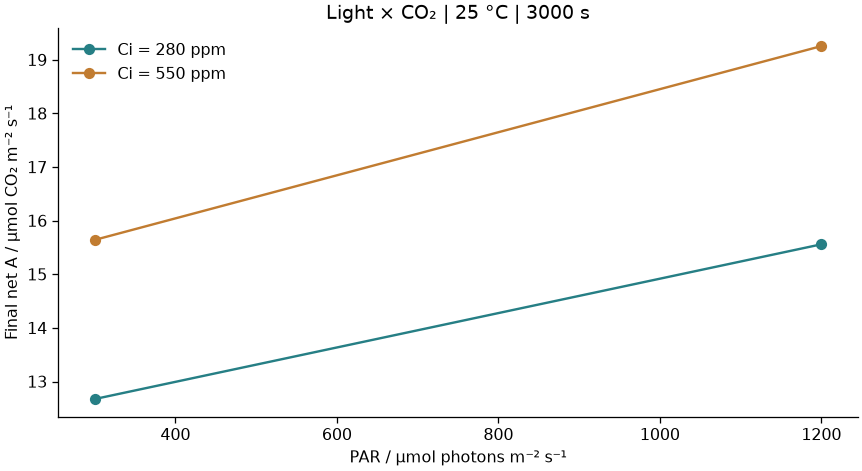

In [31]:
from c3_model.environment_practical import static_environment, print_static_table
from c3_model.plots import style
import matplotlib.pyplot as plt
style()

# INPUTS: keep two distinct, increasing levels for each factor.
d_light_levels = [300, 1200]   # PAR / µmol photons m⁻² s⁻¹
d_ci_levels = [280, 550]      # intercellular CO₂ / ppm
d_temperature = 25           # leaf temperature / °C
assert len(d_light_levels) == len(d_ci_levels) == 2
assert d_light_levels[0] < d_light_levels[1] and d_ci_levels[0] < d_ci_levels[1]

d_results = {}
for light in d_light_levels:
    for ci in d_ci_levels:
        d_results[(light, ci)] = static_environment(
            light=light, ci=ci, temperature=d_temperature)
print('Final-time rates / µmol CO₂ m⁻² s⁻¹; all cases run for 3000 s.')
print_static_table([(f'L{light}/C{ci}', row) for (light, ci), row in d_results.items()])
fig, ax = plt.subplots(figsize=(7.5, 4.1), constrained_layout=True)
for ci, color in zip(d_ci_levels, ['#267f85', '#c17c31']):
    ax.plot(d_light_levels, [d_results[(light, ci)]['A'] for light in d_light_levels],
            'o-', color=color, label=f'Ci = {ci:g} ppm')
ax.set(xlabel='PAR / µmol photons m⁻² s⁻¹', ylabel='Final net A / µmol CO₂ m⁻² s⁻¹',
       title=f'Light × CO₂ | {d_temperature:g} °C | 3000 s')
ax.legend(frameon=False)
plt.show()

# ANALYSIS: complete these after inspecting the table and figure.
d_co2_gain_low = None    # TODO: high-Ci A minus low-Ci A at d_light_levels[0]
d_co2_gain_high = None   # TODO: same subtraction at d_light_levels[1]
d_interaction = None    # TODO: d_co2_gain_high minus d_co2_gain_low
if any(x is None for x in [d_co2_gain_low, d_co2_gain_high, d_interaction]):
    print('The simulations are complete. Fill the three ANALYSIS expressions and rerun this cell.')
else:
    print(f'CO₂ effects: low light = {d_co2_gain_low:+.5f}; high light = {d_co2_gain_high:+.5f}')
    print(f'Light × CO₂ interaction = {d_interaction:+.5f} µmol CO₂ m⁻² s⁻¹')


<a id="exercise-3e"></a>
## 3E · Temperature × CO₂ · extension, 7 min

**Question:** does the model's response to warming depend on Ci? Combine 25 and
35 °C with Ci = 280 and 550 ppm at PAR = 1000. Run each case for 3000 s.
These are separate constant-temperature experiments, not a leaf warming during a run.

**Before the TODOs:**

1. Run the cell unchanged and identify the four rows. The result key is `(temperature, ci)`.
2. `e_results[(temperature, ci)]['A']` gives final net assimilation. The other rate
   fields are `['Vc']` (Rubisco carboxylation), `['PR']` (photorespiratory CO₂ loss)
   and `['Rd']` (respiratory loss in the net-A definition).
3. At low Ci, subtract A at 25 °C from A at 35 °C. Repeat at high Ci. A negative
   value means a decrease under this warming comparison; retain that sign.
4. The interaction is the warming effect at high Ci minus the warming effect at low Ci.
   Replace the three `None` values. Use the four rates below to explain the result.

```text
A = Vc - PR - Rd
warming effect = A(warm) - A(cool), at the same Ci
change in A = change in Vc - change in PR - change in Rd
```

**Record before explaining:**

| Ci / ppm | ΔVc (35 − 25 °C) | ΔPR | ΔRd | ΔA |
|---|---:|---:|---:|---:|
| 280 | fill in | fill in | fill in | fill in |
| 550 | fill in | fill in | fill in | fill in |

All entries are µmol CO₂ m⁻² s⁻¹. **Self-check:** use the same Ci for both sides
of each subtraction and confirm that the component changes reproduce ΔA. Absolute
PR can change with total carbon flux; it is not a photorespiration percentage.

**Write two sentences:** which component changes explain the warming response,
and how does that response differ between Ci levels? Do not assume that 35 °C
must improve photosynthesis or represent heat damage. The model has a generic
temperature response and no species-specific acclimation or damage mechanism.
[Reference answer 3E](#answer-3e)


Final-time rates / µmol CO₂ m⁻² s⁻¹; all cases run for 3000 s.
Case             PAR     Ci      T       Net A         Vc         PR         Rd
T25/C280         1000    280   25.0    15.55896   19.14825    2.58929    1.00000
T25/C550         1000    550   25.0    19.25557   21.75310    1.49753    1.00000
T35/C280         1000    280   35.0    11.12228   18.38437    5.26209    2.00000
T35/C550         1000    550   35.0    20.11584   25.88812    3.77228    2.00000
The simulations are complete. Fill the warming effects and interaction, then rerun.


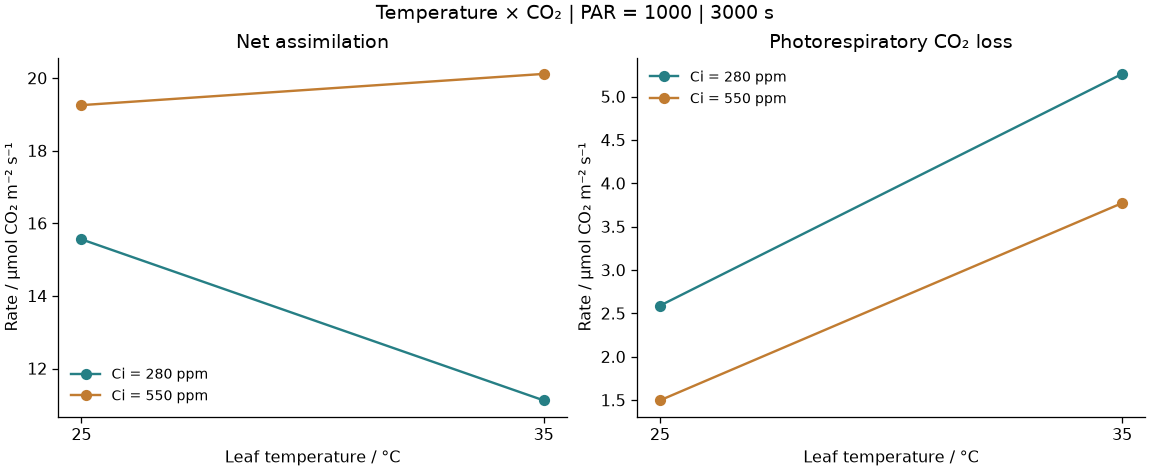

In [33]:
from c3_model.environment_practical import static_environment, print_static_table
from c3_model.plots import style
import matplotlib.pyplot as plt
style()

e_temperatures = [25, 35]   # leaf temperature / °C
e_ci_levels = [280, 550]   # intercellular CO₂ / ppm
e_light = 1000             # constant PAR
assert len(e_temperatures) == len(e_ci_levels) == 2
assert e_temperatures[0] < e_temperatures[1] and e_ci_levels[0] < e_ci_levels[1]

e_results = {}
for temperature in e_temperatures:
    for ci in e_ci_levels:
        e_results[(temperature, ci)] = static_environment(
            light=e_light, ci=ci, temperature=temperature)
print('Final-time rates / µmol CO₂ m⁻² s⁻¹; all cases run for 3000 s.')
print_static_table([(f'T{t}/C{ci}', row) for (t, ci), row in e_results.items()])
fig, axes = plt.subplots(1, 2, figsize=(10, 4.1), constrained_layout=True)
for ci, color in zip(e_ci_levels, ['#267f85', '#c17c31']):
    for ax, field, title in zip(axes, ['A', 'PR'], ['Net assimilation', 'Photorespiratory CO₂ loss']):
        ax.plot(e_temperatures, [e_results[(t, ci)][field] for t in e_temperatures],
                'o-', color=color, label=f'Ci = {ci:g} ppm')
        ax.set(xlabel='Leaf temperature / °C', ylabel='Rate / µmol CO₂ m⁻² s⁻¹', title=title)
        ax.set_xticks(e_temperatures)
        ax.legend(frameon=False, fontsize=9)
fig.suptitle(f'Temperature × CO₂ | PAR = {e_light:g} | 3000 s')
plt.show()

e_warming_low_ci = None    # TODO: warm A minus cool A at e_ci_levels[0]
e_warming_high_ci = None   # TODO: same subtraction at e_ci_levels[1]
e_interaction = None      # TODO: high-Ci warming effect minus low-Ci warming effect
if any(x is None for x in [e_warming_low_ci, e_warming_high_ci, e_interaction]):
    print('The simulations are complete. Fill the warming effects and interaction, then rerun.')
else:
    print(f'Warming effects: low Ci = {e_warming_low_ci:+.5f}; high Ci = {e_warming_high_ci:+.5f}')
    print(f'Temperature × CO₂ interaction = {e_interaction:+.5f} µmol CO₂ m⁻² s⁻¹')


<a id="exercise-3f"></a>
## 3F · Sunfleck pattern × CO₂ × temperature · extension, 10 min

**Question:** does the carbon-uptake difference between equal-photon patterns
depend on both Ci and temperature? This combines the earlier exercises.

Use patterns A and B from 3B, Ci = 280 and 550 ppm, and temperatures = 25 and
35 °C. There are **2 × 2 × 2 = 8 cases**. Background PAR stays at 300 and the
experiment lasts 600 s. Do not change enzyme amounts.

**Read these steps before the analysis:**

1. Run the next cell unchanged. The helper preconditions at PAR = 300 for each
   Ci/temperature combination, then shares that warm state between A and B.
2. Check the eight photon doses: all should be 420000 µmol photons m⁻². If you
   change a light pattern, check this equality again before interpreting timing effects.
3. The dictionary key is `(ci, temperature, pattern)`, where pattern is `'A'` or `'B'`.
   `f_results[(ci, temperature, 'B')]['C']` gives cumulative uptake for B.
4. Inside the TODO loop, replace `None` with **B cumulative C minus A cumulative C**
   at the current `ci` and `temperature`. The loop repeats this for all four environments.
5. Report which pattern fixes more carbon in each environment. A positive B − A
   difference favours B; a negative value favours A. Compare the time courses as well.

| Ci / ppm | Temperature / °C | C for A | C for B | B − A |
|---|---:|---:|---:|---:|
| 280 | 25 | fill in | fill in | fill in |
| 280 | 35 | fill in | fill in | fill in |
| 550 | 25 | fill in | fill in | fill in |
| 550 | 35 | fill in | fill in | fill in |

All three carbon columns use **mmol CO₂ m⁻²**, not instantaneous rate units.
The figures show both the time courses and their integrated uptake. A larger peak
alone does not establish a larger total.

**Optional three-factor contrast.** First calculate how warming changes B − A at
each Ci. Then subtract those two changes:

```text
gap at high Ci = (B - A at warm, high Ci) - (B - A at cool, high Ci)
gap at low Ci  = (B - A at warm, low Ci)  - (B - A at cool, low Ci)
three-factor contrast = gap at high Ci - gap at low Ci
```

Near zero means little three-factor interaction for these levels and this uptake
measure. This deterministic contrast has no statistical p-value. Explain any response
using the simulated light/energy/CO₂/temperature effects and pool dynamics; **NPQ,
stomatal opening and changing leaf temperature during the sunfleck are absent**.
[Reference answer 3F](#answer-3f)


Peak A: µmol CO₂ m⁻² s⁻¹; cumulative C: mmol CO₂ m⁻².
Case                Ci      T   Photon dose      Peak A    Cumulative C
C280/T25/A           280   25.0        420000    16.06742         8.21357
C280/T25/B           280   25.0        420000    16.05177         8.50284
C280/T35/A           280   35.0        420000    11.21888         5.00358
C280/T35/B           280   35.0        420000    11.21890         5.42780
C550/T25/A           550   25.0        420000    21.47911        10.18582
C550/T25/B           550   25.0        420000    21.56394        10.54696
C550/T35/A           550   35.0        420000    21.97871         8.90321
C550/T35/B           550   35.0        420000    20.92697         9.61139
All eight cases are complete. Fill the one expression in the analysis loop and rerun.


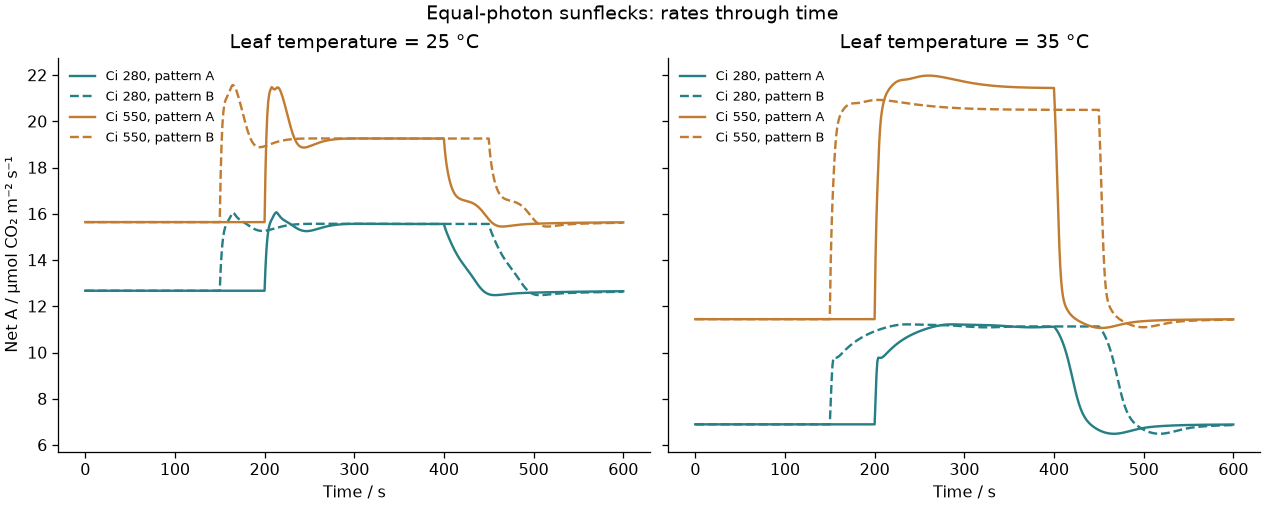

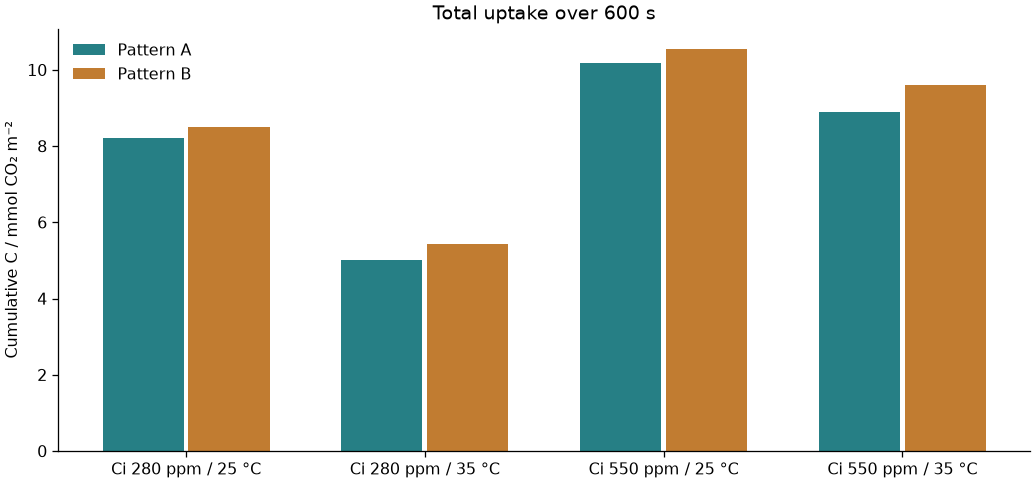

In [35]:
from c3_model.environment_practical import sunfleck_environment, print_dynamic_table
from c3_model.plots import style
import numpy as np
import matplotlib.pyplot as plt
style()

f_ci_levels = [280, 550]     # intercellular CO₂ / ppm
f_temperatures = [25, 35]    # constant leaf temperature in each run / °C
f_programs = {
    'A': dict(high=1500, start=200, end=400),
    'B': dict(high=1100, start=150, end=450),
}  # Both use background PAR = 300 and duration = 600 s.
assert len(f_ci_levels) == len(f_temperatures) == 2
assert f_ci_levels[0] < f_ci_levels[1] and f_temperatures[0] < f_temperatures[1]
assert set(f_programs) == {'A', 'B'}

f_results = {}
for ci in f_ci_levels:
    for temperature in f_temperatures:
        for pattern, program in f_programs.items():
            f_results[(ci, temperature, pattern)] = sunfleck_environment(
                ci=ci, temperature=temperature, **program)
doses = [row['photon_dose'] for row in f_results.values()]
np.testing.assert_allclose(doses, doses[0], rtol=0, atol=1e-8,
    err_msg='The light patterns must have equal photon doses for this comparison.')
print('Peak A: µmol CO₂ m⁻² s⁻¹; cumulative C: mmol CO₂ m⁻².')
print_dynamic_table([(f'C{ci}/T{t}/{pattern}', row)
    for (ci, t, pattern), row in f_results.items()])

fig, axes = plt.subplots(1, 2, figsize=(11, 4.4), sharey=True, constrained_layout=True)
for ax, temperature in zip(axes, f_temperatures):
    for ci, color in zip(f_ci_levels, ['#267f85', '#c17c31']):
        for pattern, line in [('A', '-'), ('B', '--')]:
            row = f_results[(ci, temperature, pattern)]
            ax.plot(row['time'], row['A_series'], line, color=color,
                    label=f'Ci {ci:g}, pattern {pattern}')
    ax.set(xlabel='Time / s', title=f'Leaf temperature = {temperature:g} °C')
    ax.legend(frameon=False, fontsize=8)
axes[0].set_ylabel('Net A / µmol CO₂ m⁻² s⁻¹')
fig.suptitle('Equal-photon sunflecks: rates through time')
plt.show()

groups = [(ci, t) for ci in f_ci_levels for t in f_temperatures]
positions = np.arange(len(groups))
fig, ax = plt.subplots(figsize=(9, 4.2), constrained_layout=True)
for pattern, offset, color in [('A', -.18, '#267f85'), ('B', .18, '#c17c31')]:
    ax.bar(positions+offset, [f_results[(ci, t, pattern)]['C'] for ci, t in groups],
           width=.34, label=f'Pattern {pattern}', color=color)
ax.set_xticks(positions, [f'Ci {ci:g} ppm / {t:g} °C' for ci, t in groups])
ax.set(ylabel='Cumulative C / mmol CO₂ m⁻²', title='Total uptake over 600 s')
ax.legend(frameon=False)
plt.show()

f_timing_effect = {}
for ci in f_ci_levels:
    for temperature in f_temperatures:
        f_timing_effect[(ci, temperature)] = None  # TODO: B['C'] minus A['C']
if any(value is None for value in f_timing_effect.values()):
    print('All eight cases are complete. Fill the one expression in the analysis loop and rerun.')
else:
    for (ci, temperature), effect in f_timing_effect.items():
        print(f'Ci {ci:g}, {temperature:g} °C: B − A = {effect:+.6f} mmol CO₂ m⁻²')
# Optional: calculate the three-factor contrast using the recipe above.


## 4. Solutions and discussion · 4 min
[Review solutions 3A–3C](04_Worked_Solutions.ipynb#solution-3), then return to the
[synthesis and submission task](00_Introduction.ipynb).
The additional [3D–3F worked answers](04_Worked_Solutions.ipynb#answer-3d)
are also included below. Attempt the extension exercises before opening them.
These are model calculations under the stated assumptions, not measured crop performance.


<a id="reference-answer"></a>
## Reference answers 3A–3C · Sunflecks and cumulative uptake
**3A.** Use `1500 if 200 <= t < 400 else 300` and `breakpoints=[200, 400]`.
The onset at 200 s belongs to the high-light interval; at 400 s the input returns to background.

**3B.** Both inputs integrate to 420000 µmol photons m⁻². Start from the same low-light
preconditioned state. Calculate cumulative CO₂ using `np.trapezoid(A, time)/1000`.
Integrate the piecewise-constant photon input analytically, avoiding trapezoidal errors at jumps.

**3C.** The light response is nonlinear and metabolite pools respond over time. Equal total
light therefore need not produce equal cumulative uptake. Use the calculated peak and integral
to determine the ordering; do not infer it from treatment labels. There is no NPQ mechanism
in the model to which this difference could be attributed.

Treatment A: photon dose=420000 µmol photons m⁻²; peak net A=16.0674; cumulative CO₂=8.2136 mmol m⁻²


Treatment B: photon dose=420000 µmol photons m⁻²; peak net A=16.0518; cumulative CO₂=8.5028 mmol m⁻²


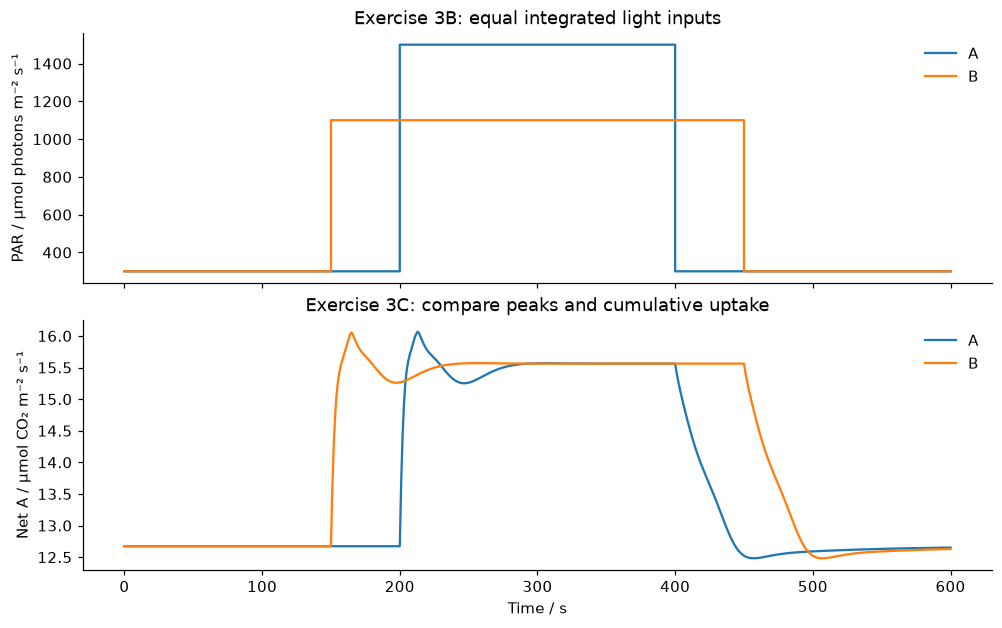

In [ ]:
from c3_model import C3Model, simulate
from c3_model.plots import style
import numpy as np
import matplotlib.pyplot as plt
style()

def my_sunfleck(t):
    return 1500 if 200 <= t < 400 else 300
breakpoints = [200, 400]
assert my_sunfleck(200) == 1500 and my_sunfleck(400) == 300
warm = simulate(C3Model(light=300), 3000).states[-1]
times = np.unique(np.r_[np.linspace(0, 600, 601), 150, 200, 400, 450])
fig, axes = plt.subplots(2, 1, figsize=(9, 5.6), sharex=True, constrained_layout=True)
for label, start, end, high in [('A', 200, 400, 1500), ('B', 150, 450, 1100)]:
    def light(t):
        return high if start <= t < end else 300
    run = simulate(C3Model(light=300), 600, initial=warm, times=times,
                   light_program=light, breakpoints=[start, end])
    photons = 300*600 + (high-300)*(end-start)
    assert photons == 420000
    carbon = np.trapezoid(run.assimilation, run.time)/1000
    print(f'Treatment {label}: photon dose={photons} µmol photons m⁻²; peak net A={run.assimilation.max():.4f}; cumulative CO₂={carbon:.4f} mmol m⁻²')
    axes[0].step(run.time, run.light, where='post', label=label)
    axes[1].plot(run.time, run.assimilation, label=label)
axes[0].set(ylabel='PAR / µmol photons m⁻² s⁻¹', title='Exercise 3B: equal integrated light inputs')
axes[1].set(xlabel='Time / s', ylabel='Net A / µmol CO₂ m⁻² s⁻¹', title='Exercise 3C: compare peaks and cumulative uptake')
for ax in axes:
    ax.legend(frameon=False)
plt.show()

<a id="answer-3d"></a>
## Reference answer 3D · Light × CO₂

Subtract within each light level before comparing the differences. With the
supplied inputs, the CO₂ effect is **+2.96754** at PAR 300 and
**+3.69662** at PAR 1200. Their interaction is **+0.72908
µmol CO₂ m⁻² s⁻¹**. A positive value means that the response to Ci is larger
at high light in this four-case comparison. Light supply constrains the
benefit available from changing CO₂; it is not appropriate to apply one
fixed CO₂ percentage gain to every light condition.

The code below shows the three expressions and runs independently. If you
already changed the 3D inputs in this kernel, it uses those choices without
resetting them; otherwise it uses the supplied inputs. The numbers in this
paragraph refer only to the supplied inputs. No statistical inference is made.


In [40]:
def _reference_3d():
    from c3_model.environment_practical import static_environment, print_static_table
    # Respect the student's selected inputs without overwriting them.
    lights = globals().get('d_light_levels', [300, 1200])
    cis = globals().get('d_ci_levels', [280, 550])
    temperature = globals().get('d_temperature', 25)
    rows = {(light, ci): static_environment(light=light, ci=ci, temperature=temperature)
            for light in lights for ci in cis}
    print_static_table([(f'L{light}/C{ci}', row) for (light, ci), row in rows.items()])
    low_gain = rows[(lights[0], cis[1])]['A'] - rows[(lights[0], cis[0])]['A']
    high_gain = rows[(lights[1], cis[1])]['A'] - rows[(lights[1], cis[0])]['A']
    interaction = high_gain - low_gain
    print(f'CO₂ effect at low light:  {low_gain:+.6f}')
    print(f'CO₂ effect at high light: {high_gain:+.6f}')
    print(f'Light × CO₂ interaction: {interaction:+.6f} µmol CO₂ m⁻² s⁻¹')
    return low_gain, high_gain, interaction
_reference_3d_values = _reference_3d()


Case             PAR     Ci      T       Net A         Vc         PR         Rd
L300/C280         300    280   25.0    12.67340   15.81150    2.13810    1.00000
L300/C550         300    550   25.0    15.64094   17.87124    1.23030    1.00000
L1200/C280       1200    280   25.0    15.55896   19.14825    2.58929    1.00000
L1200/C550       1200    550   25.0    19.25557   21.75310    1.49753    1.00000
CO₂ effect at low light:  +2.967537
CO₂ effect at high light: +3.696618
Light × CO₂ interaction: +0.729081 µmol CO₂ m⁻² s⁻¹


<a id="answer-3e"></a>
## Reference answer 3E · Temperature × CO₂

Use warm minus cool at the same Ci. With the supplied inputs, ΔA is
**-4.43667** at Ci 280 and **+0.86027** at Ci 550. The interaction is
**+5.29694 µmol CO₂ m⁻² s⁻¹**. Compare ΔVc, ΔPR and ΔRd in the
calculated table below: the identity `ΔA = ΔVc - ΔPR - ΔRd` must hold.
A change in net A cannot be explained from the photorespiration loss alone
when carboxylation and respiratory loss also change.

At Ci 280, warming reduces Vc by about 0.764 and increases PR by 2.673 and
Rd by 1.000, together explaining the fall in net A. At Ci 550, Vc rises by
about 4.135, exceeding the added PR (2.275) and Rd (1.000), so net A rises
slightly. All these changes use µmol CO₂ m⁻² s⁻¹. The contrasting net responses
are therefore consistent with the component fluxes in this model.

These generic-model results describe the specified inputs and duration.
They do not establish a species' thermal optimum or demonstrate heat injury.
The independent code respects any existing 3E input choices; the values in
this paragraph describe the supplied inputs.


In [41]:
def _reference_3e():
    from c3_model.environment_practical import static_environment, print_static_table
    import numpy as np
    ts = globals().get('e_temperatures', [25, 35])
    cis = globals().get('e_ci_levels', [280, 550])
    light = globals().get('e_light', 1000)
    rows = {(t, ci): static_environment(light=light, ci=ci, temperature=t)
            for t in ts for ci in cis}
    print_static_table([(f'T{t}/C{ci}', row) for (t, ci), row in rows.items()])
    effects = {}
    for ci in cis:
        change = {field: rows[(ts[1], ci)][field]-rows[(ts[0], ci)][field]
                  for field in ['Vc', 'PR', 'Rd', 'A']}
        np.testing.assert_allclose(change['A'], change['Vc']-change['PR']-change['Rd'], atol=1e-10)
        effects[ci] = change['A']
        print(f'Ci {ci:g}: ΔVc={change["Vc"]:+.6f}, ΔPR={change["PR"]:+.6f}, '
              f'ΔRd={change["Rd"]:+.6f}, ΔA={change["A"]:+.6f}')
    interaction = effects[cis[1]] - effects[cis[0]]
    print(f'Temperature × CO₂ interaction: {interaction:+.6f} µmol CO₂ m⁻² s⁻¹')
    return effects[cis[0]], effects[cis[1]], interaction
_reference_3e_values = _reference_3e()


Case             PAR     Ci      T       Net A         Vc         PR         Rd
T25/C280         1000    280   25.0    15.55896   19.14825    2.58929    1.00000
T25/C550         1000    550   25.0    19.25557   21.75310    1.49753    1.00000
T35/C280         1000    280   35.0    11.12228   18.38437    5.26209    2.00000
T35/C550         1000    550   35.0    20.11584   25.88812    3.77228    2.00000
Ci 280: ΔVc=-0.763881, ΔPR=+2.672792, ΔRd=+1.000000, ΔA=-4.436674
Ci 550: ΔVc=+4.135016, ΔPR=+2.274745, ΔRd=+1.000000, ΔA=+0.860271
Temperature × CO₂ interaction: +5.296945 µmol CO₂ m⁻² s⁻¹


<a id="answer-3f"></a>
## Reference answer 3F · Three environmental factors

Calculate B − A separately in each environment, using cumulative C in
mmol CO₂ m⁻². With the supplied inputs:

| Ci / ppm | Temperature / °C | B − A / mmol CO₂ m⁻² |
|---|---:|---:|
| 280 | 25 | +0.289266 |
| 280 | 35 | +0.424227 |
| 550 | 25 | +0.361138 |
| 550 | 35 | +0.708185 |

A positive value favours pattern B; a negative value favours A. Their photon
doses match, but light-response nonlinearity and metabolite trajectories can
differ. Check the rate plot alongside the integral rather than using the peak
rate as a substitute for total uptake.

For the supplied inputs, B fixes more carbon in all four environments.
Its advantage is larger at 35 than at 25 °C at both Ci levels, and that
warming-related increase in the advantage is larger at Ci 550 than at Ci 280.
This describes these eight simulations; other treatment levels may give a
different ranking.

The optional three-factor contrast is **+0.212087 mmol CO₂ m⁻²**:
subtract the temperature change in B − A at low Ci from the same change at
high Ci. Report its magnitude as well as its sign; a small numerical contrast
does not imply a practically important effect. NPQ, stomatal dynamics and
sunfleck-induced leaf heating are not simulated.

This independent code respects existing 3F inputs. The table above is for
the supplied inputs; use the printed results if you edit the experiment.


In [42]:
def _reference_3f():
    from c3_model.environment_practical import sunfleck_environment, print_dynamic_table
    import numpy as np
    cis = globals().get('f_ci_levels', [280, 550])
    ts = globals().get('f_temperatures', [25, 35])
    programs = globals().get('f_programs', {
        'A': dict(high=1500, start=200, end=400),
        'B': dict(high=1100, start=150, end=450)})
    rows = {(ci, t, pattern): sunfleck_environment(ci=ci, temperature=t, **program)
            for ci in cis for t in ts for pattern, program in programs.items()}
    doses = [row['photon_dose'] for row in rows.values()]
    np.testing.assert_allclose(doses, doses[0], rtol=0, atol=1e-8)
    print_dynamic_table([(f'C{ci}/T{t}/{pattern}', row)
        for (ci, t, pattern), row in rows.items()])
    timing_effect = {}
    for ci in cis:
        for t in ts:
            timing_effect[(ci, t)] = rows[(ci, t, 'B')]['C'] - rows[(ci, t, 'A')]['C']
            print(f'Ci {ci:g}, {t:g} °C: B − A = {timing_effect[(ci, t)]:+.6f} mmol CO₂ m⁻²')
    gap_high = timing_effect[(cis[1], ts[1])] - timing_effect[(cis[1], ts[0])]
    gap_low = timing_effect[(cis[0], ts[1])] - timing_effect[(cis[0], ts[0])]
    contrast = gap_high - gap_low
    print(f'Three-factor contrast = {contrast:+.6f} mmol CO₂ m⁻²')
    return timing_effect, contrast
_reference_3f_values = _reference_3f()


Case                Ci      T   Photon dose      Peak A    Cumulative C
C280/T25/A           280   25.0        420000    16.06742         8.21357
C280/T25/B           280   25.0        420000    16.05177         8.50284
C280/T35/A           280   35.0        420000    11.21888         5.00358
C280/T35/B           280   35.0        420000    11.21890         5.42780
C550/T25/A           550   25.0        420000    21.47911        10.18582
C550/T25/B           550   25.0        420000    21.56394        10.54696
C550/T35/A           550   35.0        420000    21.97871         8.90321
C550/T35/B           550   35.0        420000    20.92697         9.61139
Ci 280, 25 °C: B − A = +0.289266 mmol CO₂ m⁻²
Ci 280, 35 °C: B − A = +0.424227 mmol CO₂ m⁻²
Ci 550, 25 °C: B − A = +0.361138 mmol CO₂ m⁻²
Ci 550, 35 °C: B − A = +0.708185 mmol CO₂ m⁻²
Three-factor contrast = +0.212087 mmol CO₂ m⁻²
